# Strategic Diplomacy AI: Dynamic Constraint Satisfaction and Adversarial Multi-Agent Negotiation

## Key Constraints Overview:
- **6 factions** forming 15 possible pairs
- **9 total meeting slots** (3 sessions/day × 3 days)
- Only **9 out of 15 faction pairs** will actually meet
- No faction can use the same room in consecutive sessions
- Factions need at least one slot break between sessions on the same day
- Rival factions can only meet in neutral rooms

## Part A: Adaptive Diplomatic Scheduling (CSP)

### Problem Structure:
- **Variables**: 9 time slots (Day × TimeSlot)
- **Values**: (Faction1, Faction2, Room) assignments
- **Key Insight**: We're assigning faction meetings to time slots, not all pairs will meet

### Cell 0: Define problem constants and setup

In [93]:
import random
import math
import copy
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Define factions
factions = ['Alpha', 'Beta', 'Gamma', 'Delta', 'Epsilon', 'Zeta']

# Define time structure
days = ['Day1', 'Day2', 'Day3']
time_slots = ['Morning', 'Afternoon', 'Evening']
rooms = ['RoomA', 'RoomB', 'RoomC']

# Define rival relationships (factions that require neutral rooms)
rival_pairs = [('Alpha', 'Delta'), ('Beta', 'Epsilon'), ('Gamma', 'Zeta')]

# Define neutral rooms
neutral_rooms = ['RoomB']  # Only RoomB is neutral

# Create all possible faction pairs
faction_pairs = [(f1, f2) for i, f1 in enumerate(factions) for f2 in factions[i+1:]]
print(f"Total faction pairs: {len(faction_pairs)}")
print(f"Faction pairs: {faction_pairs}")

Total faction pairs: 15
Faction pairs: [('Alpha', 'Beta'), ('Alpha', 'Gamma'), ('Alpha', 'Delta'), ('Alpha', 'Epsilon'), ('Alpha', 'Zeta'), ('Beta', 'Gamma'), ('Beta', 'Delta'), ('Beta', 'Epsilon'), ('Beta', 'Zeta'), ('Gamma', 'Delta'), ('Gamma', 'Epsilon'), ('Gamma', 'Zeta'), ('Delta', 'Epsilon'), ('Delta', 'Zeta'), ('Epsilon', 'Zeta')]


### Cell 1: Define CSP variables and domains

In [94]:
# Important: We have 9 time slots total (3 per day × 3 days)
# But 15 faction pairs, so only 9 pairs will actually meet

# All possible time slots
all_time_slots = [(d, t) for d in days for t in time_slots]
print(f"Total time slots available: {len(all_time_slots)}")

# Variables: Each time slot needs exactly one meeting
# Variable format: "Day_TimeSlot" -> (faction1, faction2, room)
variables = [f"{day}_{time}" for day in days for time in time_slots]

# Domain: For each time slot, possible values are (faction_pair, room)
# We need to choose which faction pairs meet and in which room
domains = {}

for var in variables:
    # Use different names for the loop variables to avoid shadowing the 'time' module
    # and the 'days' list.
    current_day_str, current_time_str = var.split('_') # Changed 'day' to 'current_day_str' and 'time' to 'current_time_str'
    domain_values = []

    # Each slot can have any faction pair in any valid room
    for pair in faction_pairs:
        f1, f2 = pair
        is_rival = (f1, f2) in rival_pairs or (f2, f1) in rival_pairs

        if is_rival:
            # Rival pairs can only use neutral rooms
            for room in neutral_rooms:
                domain_values.append((f1, f2, room))
        else:
            # Non-rival pairs can use any room
            for room in rooms:
                domain_values.append((f1, f2, room))

    domains[var] = domain_values

print(f"Variables (time slots): {len(variables)}")
print(f"Domain size per slot: {len(domains[variables[0]])}")
print(f"Total faction pairs: {len(faction_pairs)} (but only 9 will meet)")

Total time slots available: 9
Variables (time slots): 9
Domain size per slot: 39
Total faction pairs: 15 (but only 9 will meet)


### Cell 2: Helper functions for constraint checking

In [95]:
def get_time_index(time_slot):
    """Get numerical index for time slot"""
    return time_slots.index(time_slot)

def get_day_index(day):
    """Get numerical index for day"""
    return days.index(day)

def are_consecutive_sessions(slot1, slot2):
    """Check if two slots are consecutive"""
    day1, time1, _ = slot1
    day2, time2, _ = slot2
    
    d1_idx = get_day_index(day1)
    d2_idx = get_day_index(day2)
    t1_idx = get_time_index(time1)
    t2_idx = get_time_index(time2)
    
    # Same day consecutive times
    if d1_idx == d2_idx and abs(t1_idx - t2_idx) == 1:
        return True
    
    # Cross-day consecutive (evening to next morning)
    if d2_idx - d1_idx == 1 and t1_idx == 2 and t2_idx == 0:
        return True
    if d1_idx - d2_idx == 1 and t2_idx == 2 and t1_idx == 0:
        return True
    
    return False

def same_day_sessions(slot1, slot2):
    """Check if two slots are on the same day"""
    return slot1[0] == slot2[0]

def has_sufficient_break(slot1, slot2):
    """Check if there's at least one slot break between sessions on same day"""
    if not same_day_sessions(slot1, slot2):
        return True
    
    t1_idx = get_time_index(slot1[1])
    t2_idx = get_time_index(slot2[1])
    
    return abs(t1_idx - t2_idx) > 1

### Cell 3: Constraint validation function

In [96]:
def is_assignment_valid(assignment):
    """Validate all constraints for current assignment"""
    # Track which faction pairs have already met
    pairs_used = set()

    # Track faction schedules for consecutive room checking
    faction_sessions = {f: [] for f in factions}

    # Build a schedule from the assignment
    for var, (f1, f2, room) in assignment.items():
        # 'day_str' and 'time_str' are local to this function's scope or this loop
        day_str, time_str = var.split('_')

        # Constraint: No faction pair meets more than once
        pair_key = tuple(sorted([f1, f2]))
        if pair_key in pairs_used:
            return False
        pairs_used.add(pair_key)

        # Add session info for each faction
        session_info = (day_str, time_str, room)
        faction_sessions[f1].append(session_info)
        faction_sessions[f2].append(session_info)

    # Check faction-specific constraints
    for faction, sessions in faction_sessions.items():
        if len(sessions) <= 1:  # Constraint applies if faction has 2 or more sessions
            continue

        # Sort sessions chronologically for this specific faction
        # sorted_sessions_for_faction contains (day_str, time_str, room_str) tuples
        sorted_sessions_for_faction = sorted(sessions,
                                             key=lambda x: (get_day_index(x[0]), get_time_index(x[1])))

        # Constraint 1 (NEW): A faction cannot have two of its own consecutive meetings in the same room.
        # "Consecutive" means adjacent in their personal sorted list of meetings.
        for i in range(len(sorted_sessions_for_faction) - 1):
            _curr_day, _curr_time, curr_room = sorted_sessions_for_faction[i]
            _next_day, _next_time, next_room = sorted_sessions_for_faction[i+1]

            if curr_room == next_room:
                return False

        # Constraint 2 (EXISTING): At least one slot break between sessions on same day for a faction.
        # This means a faction cannot be in Day1_Morning and Day1_Afternoon, regardless of room.
        sessions_by_day = {}
        for day_s, time_s, room_s in sorted_sessions_for_faction: # Use already sorted sessions
            if day_s not in sessions_by_day:
                sessions_by_day[day_s] = []
            sessions_by_day[day_s].append((time_s, room_s)) # Store (time_str, room_str)

        for day_key, day_meetings_list in sessions_by_day.items():
            # day_meetings_list is already sorted by time because sorted_sessions_for_faction was sorted.
            if len(day_meetings_list) > 1:
                for i in range(len(day_meetings_list) - 1):
                    time1_str = day_meetings_list[i][0]
                    time2_str = day_meetings_list[i+1][0]

                    time1_idx = get_time_index(time1_str)
                    time2_idx = get_time_index(time2_str)

                    # Must have at least one slot break (e.g., Morning and Evening is OK, Morning and Afternoon is NOT)
                    if time2_idx - time1_idx <= 1:
                        return False
    return True

### Cell 4: AC-3 Arc Consistency

In [97]:
def revise(domains, xi, xj):
    """Remove values from domain of xi that are inconsistent with xj"""
    revised = False
    new_domain = []
    
    for x_val in domains[xi]:
        # x_val = (faction1, faction2, room) for time slot xi
        x_f1, x_f2, x_room = x_val
        x_pair = tuple(sorted([x_f1, x_f2]))
        
        # Check if there exists a valid value for xj
        has_valid_partner = False
        
        for y_val in domains[xj]:
            y_f1, y_f2, y_room = y_val
            y_pair = tuple(sorted([y_f1, y_f2]))
            
            # Different faction pairs (no pair meets twice)
            if x_pair == y_pair:
                continue
            
            # Check constraints between these assignments
            temp_assignment = {xi: x_val, xj: y_val}
            if is_assignment_valid(temp_assignment):
                has_valid_partner = True
                break
        
        if has_valid_partner:
            new_domain.append(x_val)
        else:
            revised = True
    
    domains[xi] = new_domain
    return revised

def ac3(domains):
    """AC-3 algorithm for arc consistency"""
    # Create arcs between all pairs of variables (time slots)
    queue = [(xi, xj) for xi in variables for xj in variables if xi != xj]
    
    iterations = 0
    while queue and iterations < 1000:  # Safety limit
        iterations += 1
        xi, xj = queue.pop(0)
        
        if revise(domains, xi, xj):
            if not domains[xi]:
                print(f"Domain of {xi} became empty!")
                return False
            
            # Add all arcs (xk, xi) back to queue
            for xk in variables:
                if xk != xi and xk != xj:
                    queue.append((xk, xi))
    
    print(f"AC-3 completed in {iterations} iterations")
    return True

### Cell 5: Backtracking CSP solver with heuristics

In [98]:
def select_unassigned_variable(assignment, domains):
    """MRV + Degree heuristic for variable selection"""
    unassigned = [v for v in variables if v not in assignment]
    if not unassigned:
        return None
    
    # Get faction pairs already used
    used_pairs = set()
    for var, (f1, f2, room) in assignment.items():
        used_pairs.add(tuple(sorted([f1, f2])))
    
    # Calculate effective domain size (excluding already-used pairs)
    def effective_domain_size(var):
        count = 0
        for f1, f2, room in domains[var]:
            pair = tuple(sorted([f1, f2]))
            if pair not in used_pairs:
                count += 1
        return count
    
    # Sort by effective domain size (MRV)
    return min(unassigned, key=effective_domain_size)

def forward_check(domains, var, value, assignment):
    """Forward checking: remove inconsistent values from other domains"""
    new_domains = copy.deepcopy(domains)
    f1_assigned, f2_assigned, room_assigned = value  # Factions and room for current var assignment
    day_assigned, time_assigned = var.split('_')   # Day and time for current var assignment
    assigned_pair = tuple(sorted([f1_assigned, f2_assigned]))

    # Iterate through other unassigned variables
    for other_var in domains:
        if other_var != var and other_var not in assignment:
            new_domain_for_other_var = [] # Stores valid values for other_var's domain

            day_other, time_other = other_var.split('_') # Day and time for the 'other_var' being checked

            for f1_potential, f2_potential, room_potential in new_domains[other_var]:
                valid_value = True # Assume this value is initially valid

                # Constraint: No faction pair meets more than once
                pair_potential = tuple(sorted([f1_potential, f2_potential]))
                if pair_potential == assigned_pair:
                    valid_value = False

                if valid_value:
                    # Check constraints if a faction from 'var's assignment is also in this 'potential' assignment for 'other_var'
                    common_factions = {f1_assigned, f2_assigned}.intersection({f1_potential, f2_potential})

                    if common_factions:
                        # A common faction is involved in both 'var's current assignment and this potential assignment for 'other_var'.

                        # Constraint 1 (NEW): Faction's meetings (from 'var' and potential 'other_var') cannot be in the same room.
                        # If this potential meeting for the common faction is in the same room as its meeting from 'var's assignment,
                        # it's a violation according to the new rule (as these two would be consecutive for that faction,
                        # in the context of this pair-wise check).
                        if room_potential == room_assigned:
                            valid_value = False

                        # Constraint 2 (EXISTING): Same-day break for a common faction.
                        if valid_value and day_assigned == day_other: # If both meetings are on the same day
                            idx_time_assigned = get_time_index(time_assigned)
                            idx_time_other_potential = get_time_index(time_other)

                            if abs(idx_time_assigned - idx_time_other_potential) <= 1:
                                # Not enough break (e.g., Morning and Afternoon for the common faction)
                                valid_value = False
                
                if valid_value:
                    new_domain_for_other_var.append((f1_potential, f2_potential, room_potential))

            if not new_domain_for_other_var and not assignment.get(other_var): # Check if domain became empty
                 # This path leads to a dead end, but forward_check itself doesn't return False.
                 # The backtrack function will handle empty domains.
                 pass # Domain might become empty

            new_domains[other_var] = new_domain_for_other_var
    
    return new_domains

def backtrack(assignment, domains, depth=0):
    """Recursive backtracking with forward checking"""
    if len(assignment) == len(variables):
        return assignment
    
    var = select_unassigned_variable(assignment, domains)
    if var is None:
        return None
    
    # Get faction pairs already used
    used_pairs = set()
    for v, (f1, f2, r) in assignment.items():
        used_pairs.add(tuple(sorted([f1, f2])))
    
    # Try values in order, skipping already-used pairs
    for value in domains[var]:
        f1, f2, room = value
        pair = tuple(sorted([f1, f2]))
        
        # Skip if this pair already met
        if pair in used_pairs:
            continue
        
        new_assignment = assignment.copy()
        new_assignment[var] = value
        
        if is_assignment_valid(new_assignment):
            new_domains = forward_check(domains, var, value, new_assignment)
            
            # Check if any domain became empty
            domains_valid = True
            for v in variables:
                if v not in new_assignment:
                    # Count valid values (not already used pairs)
                    temp_used = used_pairs.copy()
                    temp_used.add(pair)
                    
                    valid_count = sum(1 for f1, f2, r in new_domains[v] 
                                    if tuple(sorted([f1, f2])) not in temp_used)
                    if valid_count == 0:
                        domains_valid = False
                        break
            
            if domains_valid:
                result = backtrack(new_assignment, new_domains, depth + 1)
                if result:
                    return result
    
    return None

### Cell 6: Run solver and display schedule

Running AC-3...
AC-3 completed in 72 iterations
AC-3 result: True
Domain size for Day1_Morning: 39
Domain size for Day1_Afternoon: 39
Domain size for Day1_Evening: 39

Running backtracking solver...

Solution found in 0.00 seconds!

=== DIPLOMATIC SUMMIT SCHEDULE ===
Total meetings scheduled: 9 (out of 15 possible pairs)

Faction pairs that will meet:
  - Alpha & Beta
  - Alpha & Epsilon
  - Alpha & Gamma
  - Beta & Delta
  - Beta & Zeta
  - Delta & Epsilon
  - Delta & Gamma
  - Epsilon & Zeta
  - Gamma & Zeta

--- Day1 ---
  Morning - RoomA: Alpha meets Beta
  Afternoon - RoomA: Gamma meets Delta
  Evening - RoomB: Alpha meets Epsilon

--- Day2 ---
  Morning - RoomC: Alpha meets Gamma
  Afternoon - RoomB: Beta meets Delta
  Evening - RoomA: Epsilon meets Zeta

--- Day3 ---
  Morning - RoomC: Beta meets Zeta
  Afternoon - RoomC: Delta meets Epsilon
  Evening - RoomB: Gamma meets Zeta

=== FACTION PARTICIPATION ===
  Alpha: 3 meetings
  Beta: 3 meetings
  Delta: 3 meetings
  Epsilon: 3 

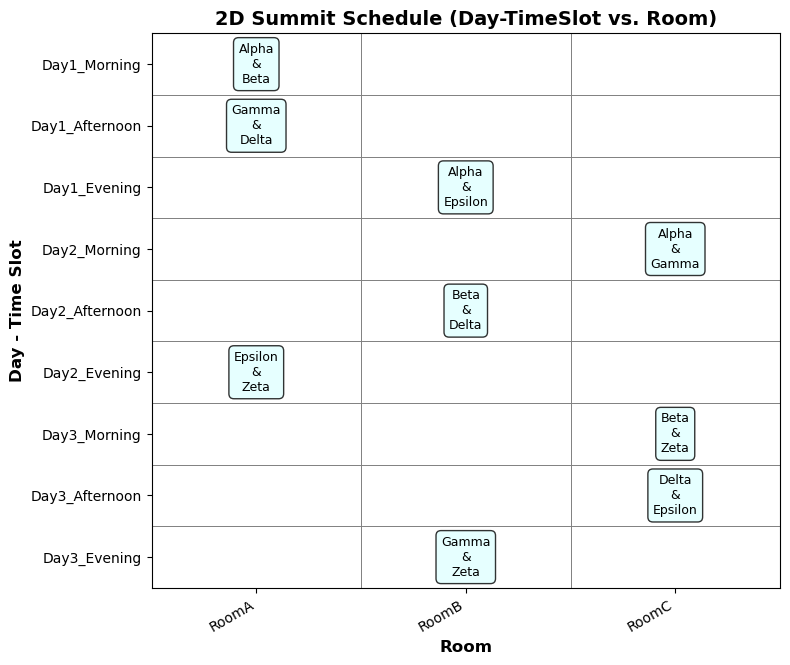

In [99]:
# Apply AC-3 first
print("Running AC-3...")
domains_copy = copy.deepcopy(domains)
ac3_result = ac3(domains_copy)
print(f"AC-3 result: {ac3_result}")

# Check domain sizes after AC-3
for var in variables[:3]:  # Show first 3
    print(f"Domain size for {var}: {len(domains_copy[var])}")

# Run backtracking solver
print("\nRunning backtracking solver...")
start_time = time.time()
solution = backtrack({}, domains_copy)
end_time = time.time()

import matplotlib.pyplot as plt
# Ensure other necessary imports like 'numpy' are present if used by matplotlib,
# but for this specific plot, only 'matplotlib.pyplot' is directly invoked.

def plot_2d_schedule(solution_dict, ordered_day_time_slots, rooms_list):
    """
    Generates a 2D plot of the summit schedule.
    Combined (Day_TimeSlot) vs. Room -> (Faction1, Faction2)
    """
    # Mappings for tick positions
    room_to_idx = {room: i for i, room in enumerate(rooms_list)}
    # The ordered_day_time_slots list (your global 'variables' list) provides the order and labels for the y-axis
    slot_to_idx = {slot: i for i, slot in enumerate(ordered_day_time_slots)}

    # Adjust figsize: width can be fixed, height depends on the number of time slots
    fig_height = max(6, len(ordered_day_time_slots) * 0.75) # Ensure a minimum height, scale with slots
    fig_width = max(8, len(rooms_list) * 2.5) # Ensure a minimum width, scale with rooms
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    # Plot the text in the grid cells
    for slot_key, (f1, f2, room_str) in solution_dict.items():
        # slot_key is like "Day1_Morning"
        # room_str is like "RoomA"
        if slot_key in slot_to_idx and room_str in room_to_idx:
            y_coord = slot_to_idx[slot_key]
            x_coord = room_to_idx[room_str]
            label = f"{f1}\n&\n{f2}" # Using newline for better fit in cells

            ax.text(x_coord, y_coord, label,
                    ha='center', va='center', fontsize=9,
                    bbox=dict(boxstyle='round,pad=0.4', fc='lightcyan', alpha=0.8)) # Bounding box for text

    # Set up axes
    ax.set_xlabel("Room", fontweight='bold', fontsize=12)
    ax.set_ylabel("Day - Time Slot", fontweight='bold', fontsize=12)

    # Set X-axis ticks and labels (Rooms)
    ax.set_xticks(list(room_to_idx.values()))
    ax.set_xticklabels(list(room_to_idx.keys()), rotation=30, ha="right") # Rotate if room names are long

    # Set Y-axis ticks and labels (Combined Day-Time Slots)
    ax.set_yticks(list(slot_to_idx.values()))
    ax.set_yticklabels(ordered_day_time_slots) # These are "Day1_Morning", etc.

    # Add grid lines to delineate cells clearly
    ax.set_xticks([x - 0.5 for x in range(len(rooms_list) + 1)], minor=True)
    ax.set_yticks([y - 0.5 for y in range(len(ordered_day_time_slots) + 1)], minor=True)
    ax.grid(which="minor", color="grey", linestyle='-', linewidth=0.7)
    ax.tick_params(which='minor', bottom=False, left=False) # Hide minor tick marks themselves

    # Set limits to ensure all cells are nicely framed
    ax.set_xlim([-0.5, len(rooms_list) - 0.5])
    ax.set_ylim([-0.5, len(ordered_day_time_slots) - 0.5])

    # Invert Y axis so that "Day1_Morning" is at the top, progressing downwards
    ax.invert_yaxis()

    plt.title("2D Summit Schedule (Day-TimeSlot vs. Room)", fontsize=14, fontweight='bold')
    plt.tight_layout() # Adjust subplot params for a tight layout
    plt.show()

if solution:
    print(f"\nSolution found in {end_time - start_time:.2f} seconds!")
    print("\n=== DIPLOMATIC SUMMIT SCHEDULE ===")
    print(f"Total meetings scheduled: {len(solution)} (out of {len(faction_pairs)} possible pairs)")
    
    # Show which pairs are meeting
    meeting_pairs = set()
    for var, (f1, f2, room) in solution.items():
        meeting_pairs.add(tuple(sorted([f1, f2])))
    
    print("\nFaction pairs that will meet:")
    for pair in sorted(meeting_pairs):
        print(f"  - {pair[0]} & {pair[1]}")
    
        # Display schedule by day
    for day in days:
        print(f"\n--- {day} ---")
        # Corrected line: 't' is replaced by 'var'.
        # 'var' is the key from the solution dictionary (e.g., "Day1_Morning", "Day1_Afternoon").
        day_sessions = [(var, var, solution[var]) for var in solution if var.startswith(day)]
        
        # This sort key expects the first element of the tuple (x[0]) to be the full time slot string.
        day_sessions.sort(key=lambda x: get_time_index(x[0].split('_')[1]))
        
        # In this loop:
        # - 'time_slot' will be the first 'var' from the tuple (e.g., "Day1_Morning").
        # - 'var' (the second variable in unpacking) will also be the 'var' from the tuple (e.g., "Day1_Morning").
        for time_slot, var, (f1, f2, room) in day_sessions:
            # 'time_val' (or 'time' as in your original code) is extracted from 'var'.
            # This 'time_val' is a local string variable (e.g., "Morning") and is fine here.
            time_val = var.split('_')[1] 
            print(f"  {time_val} - {room}: {f1} meets {f2}")
            
    # Analyze faction participation
    print("\n=== FACTION PARTICIPATION ===")
    faction_meetings = {f: 0 for f in factions}
    for var, (f1, f2, room) in solution.items():
        faction_meetings[f1] += 1
        faction_meetings[f2] += 1
    
    for faction, count in sorted(faction_meetings.items()):
        print(f"  {faction}: {count} meetings")
        # Call the new 2D plotting function
    print("\nGenerating 2D schedule plot...")
    # 'variables' is your global list: [f"{day}_{time}" for day in days for time in time_slots]
    # 'rooms' is your global list: ['RoomA', 'RoomB', 'RoomC']
    plot_2d_schedule(solution, variables, rooms)
    
else:
    print("No solution found!")
    print("This might be due to over-constrained requirements.")

### Cell 7: Dynamic CSP - Handle room failure

In [10]:
def handle_room_failure(original_solution, failed_room, failed_day, failed_time):
    """Handle dynamic room failure with minimal rescheduling"""
    print(f"\n=== ROOM FAILURE DETECTED ===")
    print(f"Failed: {failed_room} on {failed_day} {failed_time}")
    
    # Find affected meeting
    affected_var = f"{failed_day}_{failed_time}"
    
    if affected_var not in original_solution:
        print("No meeting scheduled at the failed slot.")
        return original_solution
    
    f1, f2, room = original_solution[affected_var]
    
    if room != failed_room:
        print(f"Meeting {f1}-{f2} is in {room}, not affected by {failed_room} failure.")
        return original_solution
    
    print(f"Affected meeting: {f1} & {f2} in {room}")
    
    # Try to find alternative room in same time slot
    print("\nAttempting to relocate to different room at same time...")
    
    # Check if faction pair can use other rooms
    is_rival = (f1, f2) in rival_pairs or (f2, f1) in rival_pairs
    available_rooms = neutral_rooms if is_rival else rooms
    
    # Try other rooms at same time
    for alt_room in available_rooms:
        if alt_room != failed_room:
            # Check if room is free
            room_free = True
            for var, (of1, of2, oroom) in original_solution.items():
                if var != affected_var and var == affected_var and oroom == alt_room:
                    room_free = False
                    break
            
            if room_free:
                # Check faction constraints for room change
                new_solution = original_solution.copy()
                new_solution[affected_var] = (f1, f2, alt_room)
                
                if is_assignment_valid(new_solution):
                    print(f"Successfully relocated to {alt_room}")
                    return new_solution
    
    # If can't relocate to same time, need to reschedule
    print("\nCannot relocate to same time slot. Attempting full rescheduling...")
    
    # Create partial assignment without affected meeting
    partial_assignment = {k: v for k, v in original_solution.items() if k != affected_var}
    
    # Update domains to exclude failed room at that time
    updated_domains = copy.deepcopy(domains)
    
    # Remove failed room from the specific time slot
    new_domain = []
    for f1_d, f2_d, room_d in updated_domains[affected_var]:
        if room_d != failed_room:
            new_domain.append((f1_d, f2_d, room_d))
    updated_domains[affected_var] = new_domain
    
    # Also need to ensure the affected pair can still meet
    affected_pair = tuple(sorted([f1, f2]))
    
    # Check which pairs are already scheduled
    scheduled_pairs = set()
    for var, (f1_s, f2_s, room_s) in partial_assignment.items():
        scheduled_pairs.add(tuple(sorted([f1_s, f2_s])))
    
    # Run solver with updated constraints
    new_solution = backtrack(partial_assignment, updated_domains)
    
    return new_solution

# Simulate room failure
if new_solution:
    # Pick a room failure scenario
    failed_day = "Day2"
    failed_time = "Afternoon"
    failed_room = "RoomB"  # Neutral room failure is interesting
    
    updated_solution = handle_room_failure(solution, failed_room, failed_day, failed_time)
    
    if updated_solution:
        print("\n=== UPDATED SCHEDULE AFTER ROOM FAILURE ===")
        
        # Show only the changes
        changes = []
        for var in variables:
            if var in solution and var in updated_solution:
                if solution[var] != updated_solution[var]:
                    old_f1, old_f2, old_room = solution[var]
                    new_f1, new_f2, new_room = updated_solution[var]
                    changes.append((var, 
                                  f"{old_f1}-{old_f2} in {old_room}",
                                  f"{new_f1}-{new_f2} in {new_room}"))
        
        print(f"\nTotal changes: {len(changes)}")
        for var, old, new in changes:
            day, time = var.split('_')
            print(f"  {day} {time}: {old} → {new}")
        
        # Check if all original pairs still meet
        original_pairs = set()
        new_pairs = set()
        
        for var, (f1, f2, room) in solution.items():
            original_pairs.add(tuple(sorted([f1, f2])))
        
        for var, (f1, f2, room) in updated_solution.items():
            new_pairs.add(tuple(sorted([f1, f2])))
        
        if original_pairs == new_pairs:
            print("\n✓ All original faction pairs still meet")
        else:
            print("\n⚠ Some faction pairs changed:")
            removed = original_pairs - new_pairs
            added = new_pairs - original_pairs
            for pair in removed:
                print(f"  - Removed: {pair[0]} & {pair[1]}")
            for pair in added:
                print(f"  + Added: {pair[0]} & {pair[1]}")
    else:
        print("\nFailed to find alternative schedule!")

NameError: name 'new_solution' is not defined